Archivo cargado: 1000 filas y 8 columnas
Columnas: ['CODUSU', 'REGION', 'IX_TOT', 'NIVEL_ED', 'ITF', 'DECIFR', 'IV12_3', 'II7']
Hogares con ingreso válido: 947


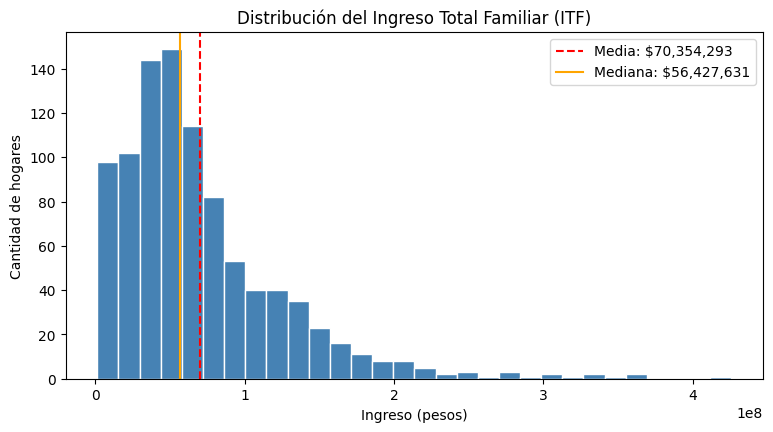

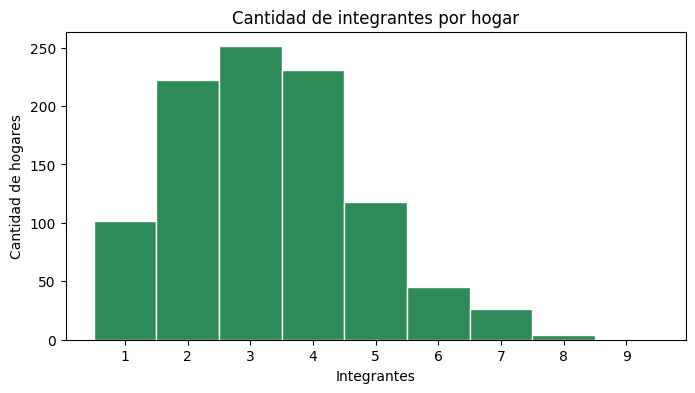

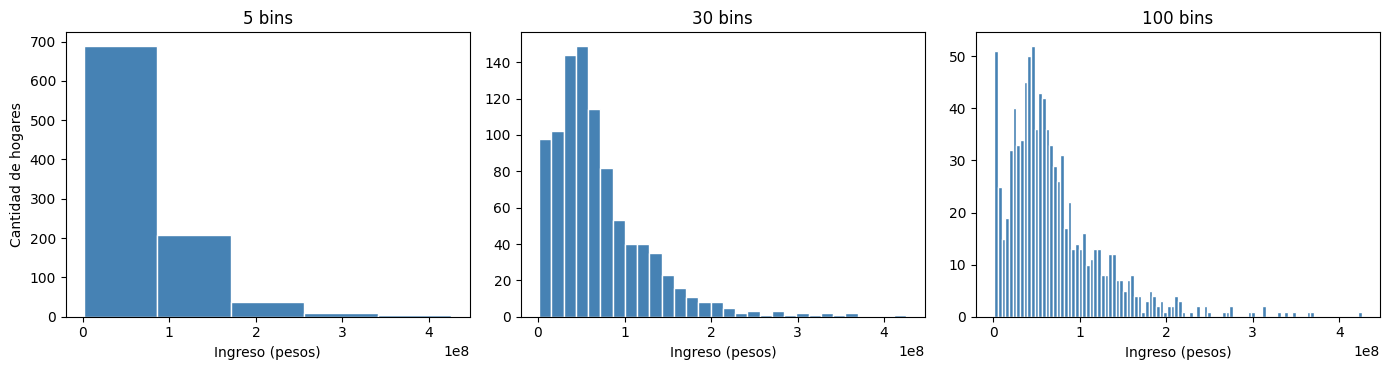

In [5]:
# Histogramas del dataset EPH (eph_tecnologia_microdatos.csv)

# Paso 1: Importar las librerías
# pandas sirve para leer y manejar la tabla de datos, numpy para
# trabajar con números (lo usamos para definir las barras) y
# matplotlib es la librería que dibuja los gráficos.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Paso 2: Cargar el archivo CSV
# Antes de ejecutar, el CSV tiene que estar subido a Colab
# (ícono de carpeta de la izquierda). Algunos CSV guardados desde
# Excel vienen con cada fila entre comillas o con ";" como separador,
# y pandas los lee como UNA sola columna. Para evitarlo, leemos el
# archivo como texto, sacamos las comillas, detectamos el separador
# mirando la primera fila y recién ahí lo convertimos en tabla (df).
import io

with open("eph_tecnologia_microdatos.csv", encoding="utf-8-sig") as f:
    lineas = [linea.strip().strip('"') for linea in f if linea.strip()]

sep = ";" if lineas[0].count(";") > lineas[0].count(",") else ","
decimal = "," if sep == ";" else "."
df = pd.read_csv(io.StringIO("\n".join(lineas)), sep=sep, decimal=decimal)
print("Archivo cargado:", df.shape[0], "filas y", df.shape[1], "columnas")
print("Columnas:", df.columns.tolist())

# Paso 3: Preparar la variable de ingreso
# Nos quedamos solo con la columna ITF (ingreso total familiar).
# Hay hogares que no respondieron el ingreso (datos faltantes, NaN)
# y plt.hist() no funciona con ellos, así que los sacamos con dropna().
itf = df["ITF"].dropna()
print("Hogares con ingreso válido:", len(itf))

# Paso 4: Histograma del ingreso (ITF)
# Un histograma divide el rango de valores en tramos iguales (bins,
# las barras) y cuenta cuántos hogares caen en cada uno.
# Eje x = ingreso, eje y = cantidad de hogares.
# Con axvline() marcamos con líneas verticales la media y la mediana
# para ver si la distribución está desparejada hacia algún lado.
plt.figure(figsize=(9, 4.5))
plt.hist(itf, bins=30, color="steelblue", edgecolor="white")
plt.axvline(itf.mean(), color="red", linestyle="--", label=f"Media: ${itf.mean():,.0f}")
plt.axvline(itf.median(), color="orange", linestyle="-", label=f"Mediana: ${itf.median():,.0f}")
plt.title("Distribución del Ingreso Total Familiar (ITF)")
plt.xlabel("Ingreso (pesos)")
plt.ylabel("Cantidad de hogares")
plt.legend()
plt.show()

# Paso 5: Histograma de integrantes del hogar (IX_TOT)
# IX_TOT toma solo números enteros (1, 2, 3), así que conviene
# definir los bins a mano. np.arange(0.5, 10.5, 1) crea cortes en
# 0,5 / 1,5 / 2,5 y de esa forma cada número entero queda justo
# en el centro de su barra.
plt.figure(figsize=(8, 4))
plt.hist(df["IX_TOT"], bins=np.arange(0.5, 10.5, 1), color="seagreen", edgecolor="white")
plt.title("Cantidad de integrantes por hogar")
plt.xlabel("Integrantes")
plt.ylabel("Cantidad de hogares")
plt.xticks(range(1, 10))
plt.show()

# Paso 6: Comparar distintas cantidades de bins
# La cantidad de bins cambia mucho cómo se ve el histograma: con
# pocos se pierde detalle y con demasiados el gráfico se vuelve
# "ruidoso". Dibujamos el mismo ingreso con 5, 30 y 100 bins, uno
# al lado del otro, usando un ciclo for para no repetir código.
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
for eje, cantidad in zip(ejes, [5, 30, 100]):
    eje.hist(itf, bins=cantidad, color="steelblue", edgecolor="white")
    eje.set_title(f"{cantidad} bins")
    eje.set_xlabel("Ingreso (pesos)")
ejes[0].set_ylabel("Cantidad de hogares")
plt.tight_layout()
plt.show()